# Parte 2 – Caracterización del ruido speckle

El **speckle** es el "granulado" que se ve en toda ecografía. No es ruido electrónico: aparece porque dentro de cada celda de resolución hay muchísimos dispersores (células, fibras) más chicos que la longitud de onda, y sus ecos se suman con fases al azar. A veces se suman en fase (punto brillante) y a veces se cancelan (punto oscuro).

En esta parte queremos **modelarlo estadísticamente** con las imágenes reales de BUSI, como pide el objetivo específico 1 del anteproyecto:

**Contenido**
1. El modelo teórico: qué esperamos encontrar
2. Elegir parches de tejido homogéneo (lejos de la lesión, sin fondo ni marcas)
3. Histograma de un parche y ajuste de Rayleigh, Gamma y Nakagami
4. Comparación de los ajustes sobre muchos parches y por clase
5. Relación media/desvío (μ/σ) contra el valor teórico 1,91
6. ¿Es multiplicativo? Varianza local vs. media, antes y después del logaritmo
7. Por qué las imágenes no cumplen la teoría: compresión logarítmica y post-procesamiento
8. Conclusiones

### Preparación

Igual que en la Parte 0: le decimos a Python dónde está nuestro código (`src/`) y activamos `autoreload`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy import stats
from scipy.stats import mannwhitneyu

from busi.datos import listar_casos, cargar_caso
from busi.config import load_config
from busi import ruido

warnings.filterwarnings("ignore", category=RuntimeWarning)   # avisos numéricos de los ajustes de scipy

casos = listar_casos()
SEED = load_config()["SEED"]          # semilla de config.yaml: siempre salen los mismos parches
print(f"{len(casos)} imágenes, SEED = {SEED}")

780 imágenes, SEED = 13


## 1. El modelo teórico

**Modelo multiplicativo.** La imagen observada es $g = f \cdot n$: $f$ es la reflectividad "verdadera" del tejido y $n$ es el speckle. En un parche de **tejido homogéneo**, $f$ es casi constante, así que el histograma del parche muestra la distribución de $n$ (escalada).

**Speckle completamente desarrollado.** Si hay muchos dispersores por celda de resolución y ninguno domina, la **amplitud** del eco (la envolvente) sigue una distribución de **Rayleigh**:

$$p(a) = \frac{a}{s^2}\, e^{-a^2/2s^2}, \qquad a \ge 0$$

Rayleigh tiene un solo parámetro (la escala $s$), así que su **forma es siempre la misma**. Por eso la relación media/desvío es una constante:

$$\frac{\mu}{\sigma} = \sqrt{\frac{\pi}{4-\pi}} \approx 1{,}91$$

**Distribuciones más generales.** Cuando hay pocos dispersores, o alguno domina (una estructura), Rayleigh deja de valer. Se usan dos familias con un parámetro de **forma** extra:
- **Nakagami** (forma $m$): con $m = 1$ es exactamente Rayleigh; $m < 1$ es speckle "pre-Rayleigh" (pocos dispersores) y $m > 1$ es más regular que Rayleigh.
- **Gamma** (forma $a$): muy usada para modelar la intensidad (amplitud al cuadrado) o la imagen ya procesada.

**El logaritmo.** Si $g = f \cdot n$, entonces $\log g = \log f + \log n$: el ruido pasa a ser **aditivo**. Con ruido multiplicativo la varianza local crece con el brillo ($\sigma \propto \mu$, o sea $\text{var} \propto \mu^2$); después del log debería quedar **constante**.

En las próximas secciones comparamos cada una de estas predicciones con las imágenes reales.

## 2. Parches de tejido homogéneo

Para que el histograma refleje el speckle y no la anatomía, necesitamos parches de **tejido**, no de lesión ni de otra cosa. `ruido.extraer_parches()` sortea posiciones al azar de parches de 32 × 32 px y **descarta** los que:

| Criterio | Por qué |
|---|---|
| Tocan la lesión **dilatada** 20 px (disco de radio 20) | El borde del tumor y el halo que lo rodea no son tejido homogéneo. La dilatación (Segmentación II) agranda la máscara para dejar un margen de seguridad |
| Tienen media < 20, desvío < 3 o algún píxel en 0 | Es el **fondo negro** fuera del sector de la sonda, o zonas sin señal (sombra profunda) |
| Tienen algún píxel ≥ 250 | Son **marcas del ecógrafo** (calipers, textos): vimos en la Parte 0 que el blanco puro casi siempre es marca, no tejido |
| Se superponen con otro parche ya elegido | Para que cada parche aporte información distinta |

El sorteo usa un generador `rng` con la `SEED` de `config.yaml`, así el resultado es reproducible.

Primero lo vemos en un ejemplo de cada clase: en **rojo** el borde de la lesión, en **naranja** la zona prohibida (lesión dilatada) y en **verde** los parches elegidos.

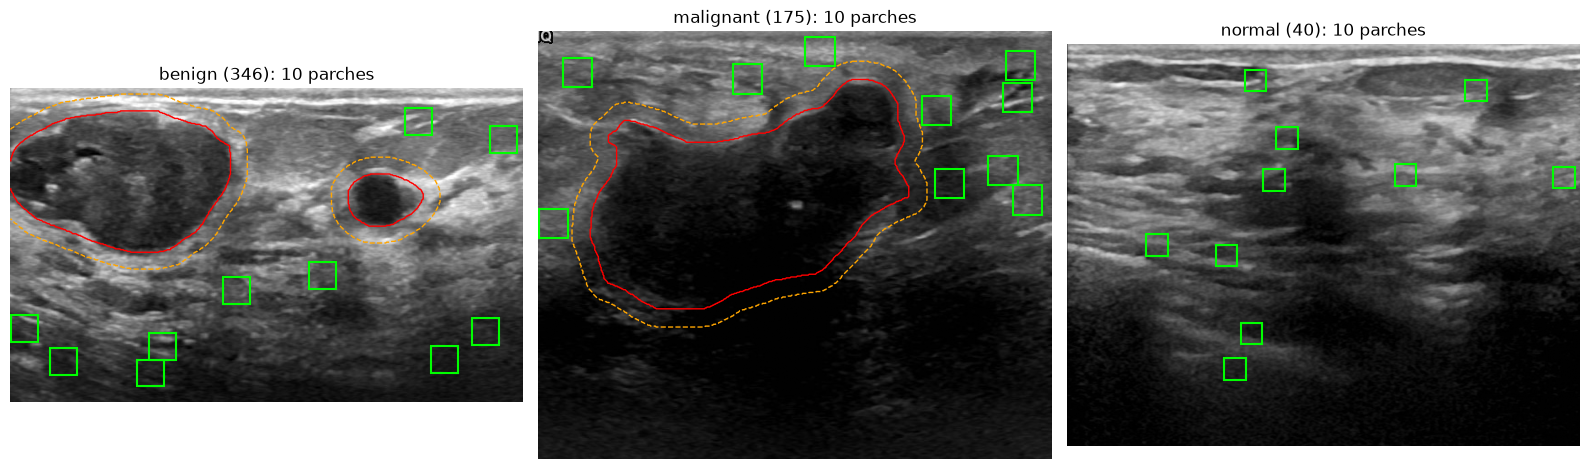

In [3]:
rng = np.random.default_rng(SEED)
ejemplos = [casos[casos["clase"] == c].sample(1, random_state=SEED).iloc[0]
            for c in ["benign", "malignant", "normal"]]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
parches_ejemplo = []
for ax, caso in zip(axes, ejemplos):
    img, mascara = cargar_caso(caso)
    parches, esquinas = ruido.extraer_parches(img, mascara, tam=32, n=10, margen=20, rng=rng)
    parches_ejemplo.append((caso, parches))

    disco = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41))
    prohibida = cv2.dilate(mascara.astype(np.uint8), disco)

    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    if mascara.any():
        ax.contour(mascara, levels=[0.5], colors="red", linewidths=1)
        ax.contour(prohibida, levels=[0.5], colors="orange", linewidths=1, linestyles="--")
    for (y, x) in esquinas:
        ax.add_patch(plt.Rectangle((x, y), 32, 32, fill=False, edgecolor="lime", linewidth=1.5))
    ax.set_title(f"{caso['id']}: {len(parches)} parches")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:** los parches quedan repartidos por el tejido, fuera de la zona naranja y lejos de las marcas. Ninguno cae en el fondo negro.

Ojo: **"lejos de la lesión" no significa "homogéneo"**. Algunos parches caen sobre fibras, ligamentos de Cooper o el límite entre grasa y tejido glandular, que son **estructura**, no speckle. Eso va a hacer que los histogramas de algunos parches sean más anchos o tengan dos modos. No los filtramos por homogeneidad a propósito: un criterio como "quedarse con los parches con μ/σ cerca de 1,91" sesgaría justo lo que queremos medir.

Ahora miramos los parches de cerca, de a uno:

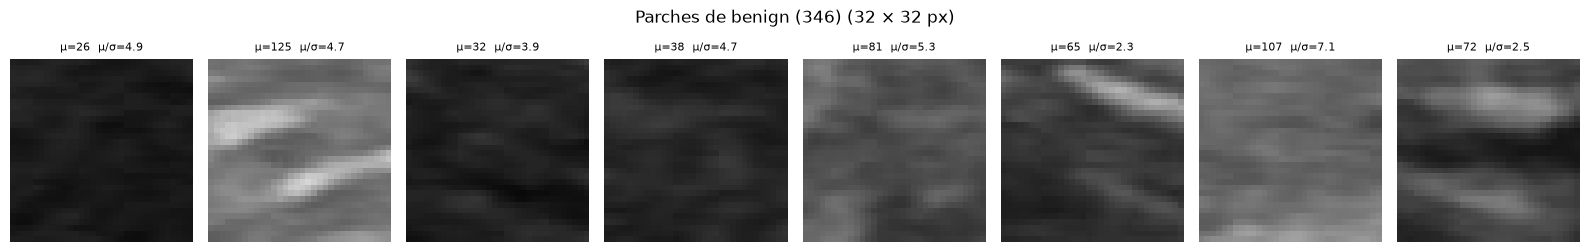

In [4]:
caso, parches = parches_ejemplo[0]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, p in zip(axes, parches):
    ax.imshow(p, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"μ={p.mean():.0f}  μ/σ={ruido.razon_media_desvio(p):.1f}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Parches de {caso['id']} (32 × 32 px)")
plt.tight_layout()
plt.show()

**Qué vemos:** el speckle se ve como **granos suaves de varios píxeles**, más alargados en sentido lateral (horizontal) que en profundidad, y no como píxeles sueltos independientes. Eso pasa porque la celda de resolución del ecógrafo es más ancha que alta, y porque el equipo interpola y suaviza la imagen. Algunos parches (μ=125, μ=65) muestran además **fibras** brillantes: son estructura del tejido, no speckle. Es la primera diferencia con un ruido "de libro": los píxeles vecinos están **correlacionados**. Lo vamos a tener en cuenta al interpretar el test KS (sección 4).

## 3. Histograma de un parche y ajuste de distribuciones

`ruido.ajustar_distribuciones()` ajusta Rayleigh, Gamma y Nakagami a los 1024 píxeles de un parche por **máxima verosimilitud** (`scipy.stats.<dist>.fit`), con `loc = 0` fijo como en el modelo físico (la amplitud empieza en 0). Para cada ajuste devuelve:

- **log-verosimilitud** (`loglik`): qué tan probable es ver estos datos con la distribución ajustada. Más alta = mejor.
- **AIC** = 2·(n° de parámetros) − 2·loglik: igual que la loglik, pero **penaliza** tener más parámetros (Rayleigh tiene 1, Gamma y Nakagami 2). Más bajo = mejor. Lo usamos para elegir la "ganadora".
- **Test de Kolmogorov-Smirnov** (`ks`, `p_ks`): el estadístico D es la máxima distancia entre la distribución acumulada de los datos y la del modelo (0 = idénticas).

Elegimos 4 parches de distinto brillo para ver si el comportamiento cambia.

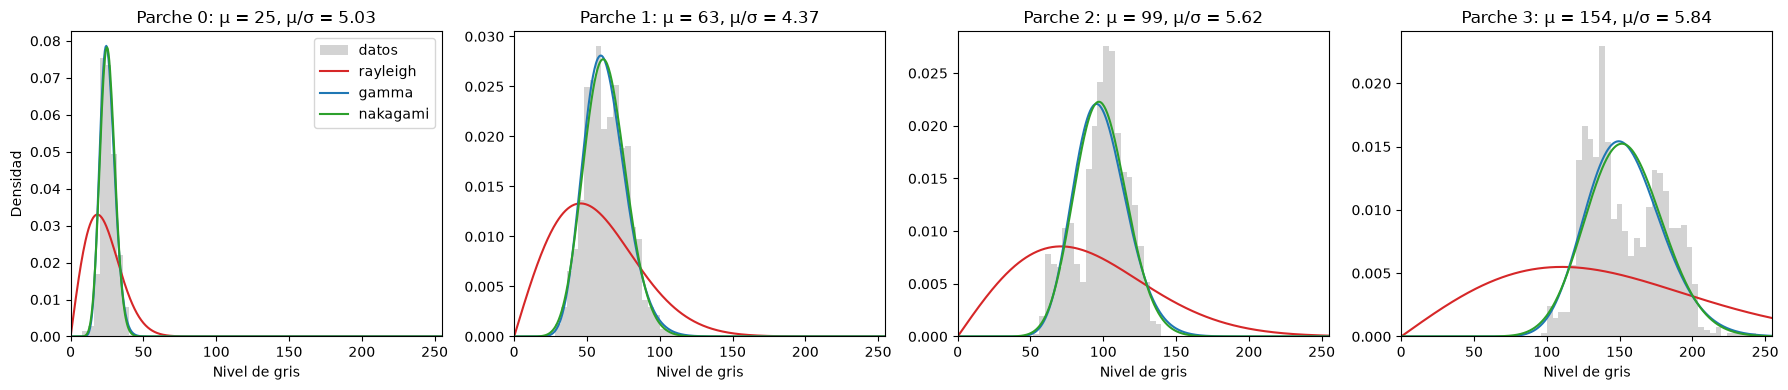

media    μ/σ    loglik        AIC   KS D   p KS
parche distribución                                                   
0      rayleigh       25.495  5.031 -3691.231   7384.461  0.362  0.000
       gamma          25.495  5.031 -3119.218   6242.435  0.066  0.000
       nakagami       25.495  5.031 -3113.488   6230.977  0.071  0.000
1      rayleigh       62.861  4.371 -4634.368   9270.736  0.300  0.000
       gamma          62.861  4.371 -4175.104   8354.208  0.041  0.061
       nakagami       62.861  4.371 -4174.088   8352.177  0.049  0.013
2      rayleigh       98.737  5.619 -5066.586  10135.172  0.311  0.000
       gamma          98.737  5.619 -4419.855   8843.709  0.096  0.000
       nakagami       98.737  5.619 -4401.432   8806.864  0.084  0.000
3      rayleigh      153.893  5.845 -5515.794  11033.588  0.396  0.000
       gamma         153.893  5.845 -4787.057   9578.115  0.093  0.000
       nakagami      153.893  5.845 -4792.017   9588.034  0.102  0.000

In [5]:
rng = np.random.default_rng(SEED)
img, mascara = cargar_caso(ejemplos[0])
parches, _ = ruido.extraer_parches(img, mascara, n=40, rng=rng)
orden = np.argsort(parches.mean(axis=(1, 2)))
elegidos = parches[orden[[0, len(orden) // 3, 2 * len(orden) // 3, -1]]]   # del más oscuro al más claro

colores = {"rayleigh": "tab:red", "gamma": "tab:blue", "nakagami": "tab:green"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
filas = []
for i, (ax, p) in enumerate(zip(axes, elegidos)):
    res = ruido.ajustar_distribuciones(p)
    x = np.linspace(0, 255, 500)
    ax.hist(p.ravel(), bins=np.arange(0, 257, 4), density=True, color="lightgray", label="datos")
    for nombre, r in res.items():
        ax.plot(x, getattr(stats, nombre).pdf(x, *r["params"]), color=colores[nombre], label=nombre)
        filas.append({"parche": i, "media": p.mean(), "μ/σ": ruido.razon_media_desvio(p), "distribución": nombre,
                      "loglik": r["loglik"], "AIC": r["aic"], "KS D": r["ks"], "p KS": r["p_ks"]})
    ax.set_title(f"Parche {i}: μ = {p.mean():.0f}, μ/σ = {ruido.razon_media_desvio(p):.2f}")
    ax.set_xlabel("Nivel de gris")
    ax.set_xlim(0, 255)
axes[0].set_ylabel("Densidad")
axes[0].legend()
plt.tight_layout()
plt.show()

pd.DataFrame(filas).set_index(["parche", "distribución"]).round(3)

**Qué vemos:**
- **Rayleigh ajusta muy mal** en todos los parches: es mucho más ancha que el histograma real y empieza en 0. Su forma es fija (μ/σ = 1,91), pero los parches reales son mucho más "angostos" respecto de su media (μ/σ entre 4,4 y 5,8, más del doble de 1,91).
- **Gamma y Nakagami** siguen bien el histograma porque tienen un parámetro de forma libre. Su log-verosimilitud es mucho más alta y su KS D mucho más chico que los de Rayleigh.
- El parche 3 (el más claro) tiene un histograma con dos "jorobas": cae sobre una fibra brillante, o sea que mezcla speckle y **estructura**. Ninguna de las tres lo describe del todo.
- Aun así el **p-valor del KS es < 0,05 en 3 de los 4 parches** también para Gamma y Nakagami, o sea que formalmente se rechazan. Lo discutimos en la sección siguiente: con 1024 píxeles correlacionados y valores enteros, el test es demasiado estricto.

## 4. Comparación sobre muchos parches y por clase

Un parche no alcanza para concluir. Tomamos **5 parches por imagen** en las 780 imágenes (~3900 parches) y ajustamos las tres distribuciones a cada uno. Tarda alrededor de medio minuto.

In [6]:
rng = np.random.default_rng(SEED)
nombres = ["rayleigh", "gamma", "nakagami"]
filas = []
todos_los_parches = []                # los guardamos para la sección 7
for _, caso in casos.iterrows():
    img, mascara = cargar_caso(caso)
    parches, esquinas = ruido.extraer_parches(img, mascara, n=5, rng=rng)
    todos_los_parches.extend(parches)
    for p, (y, x) in zip(parches, esquinas):
        res = ruido.ajustar_distribuciones(p)
        fila = {"id": caso["id"], "clase": caso["clase"], "media": p.mean(), "desvio": p.std(),
                "mu_sigma": ruido.razon_media_desvio(p), "profundidad": y / img.shape[0],
                "m_nakagami": res["nakagami"]["params"][0]}
        for nombre in nombres:
            fila[f"loglik_{nombre}"] = res[nombre]["loglik"]
            fila[f"aic_{nombre}"] = res[nombre]["aic"]
            fila[f"ks_{nombre}"] = res[nombre]["ks"]
            fila[f"p_{nombre}"] = res[nombre]["p_ks"]
        filas.append(fila)

parches_df = pd.DataFrame(filas)
aics = parches_df[[f"aic_{n}" for n in nombres]].to_numpy()
parches_df["mejor"] = np.array(nombres)[aics.argmin(axis=1)]     # la de menor AIC en cada parche
print(f"{len(parches_df)} parches de {parches_df['id'].nunique()} imágenes")

3900 parches de 780 imágenes


### 4.1 Tabla comparativa

Para cada distribución resumimos:
- **% mejor (AIC):** en qué porcentaje de los parches fue la de menor AIC;
- **loglik y KS D medianos;**
- **% p KS > 0,05:** en qué porcentaje de parches el test KS *no* rechaza el modelo.

In [7]:
def tabla_comparativa(df):
    return pd.DataFrame({
        "% mejor (AIC)": [100 * (df["mejor"] == n).mean() for n in nombres],
        "loglik mediana": [df[f"loglik_{n}"].median() for n in nombres],
        "KS D mediano": [df[f"ks_{n}"].median() for n in nombres],
        "% p KS > 0,05": [100 * (df[f"p_{n}"] > 0.05).mean() for n in nombres],
    }, index=nombres).round(3)

tabla_comparativa(parches_df)

,% mejor (AIC),loglik mediana,KS D mediano,"% p KS > 0,05"
rayleigh,0.333,-5003.557,0.329,0.051
gamma,64.308,-4370.234,0.078,5.282
nakagami,35.359,-4385.746,0.082,4.795


**Qué vemos:**
- **Rayleigh casi nunca gana** (0,3 % de los parches) y su KS D mediano (~0,33) es cuatro veces el de las otras dos: el histograma real está muy lejos de una Rayleigh.
- **Gamma gana en ~64 % de los parches y Nakagami en ~35 %.** Las dos tienen ajustes muy parecidos (KS D ~0,08), así que la diferencia entre ellas es chica. Gamma tiene una cola derecha un poco más larga, que se adapta mejor a los píxeles brillantes sueltos.
- El test KS rechaza **las tres** en la gran mayoría de los parches (solo ~5 % con p > 0,05 para Gamma y Nakagami). No significa que sean malos modelos sino que el test es demasiado exigente acá:
  1. los píxeles **no son independientes** (vimos que el speckle forma granos de varios píxeles), y el KS supone muestras independientes: con 1024 píxeles correlacionados hay en realidad muchas menos "muestras efectivas" y el p-valor sale demasiado chico;
  2. los valores son **enteros** (0 a 255), y la acumulada de los datos tiene escalones que una curva continua no puede seguir;
  3. los parámetros se estimaron con los **mismos datos** que se testean.

  Por eso para **comparar** modelos usamos el estadístico D y el AIC (que miden "cuál ajusta mejor"), y no el p-valor (que pregunta "¿ajusta perfecto?").

### 4.2 Por clase

¿El tejido de las imágenes benignas, malignas y normales se comporta distinto? Repetimos la tabla separando por clase.

In [8]:
pd.concat({c: tabla_comparativa(parches_df[parches_df["clase"] == c]) for c in ["benign", "malignant", "normal"]})

% mejor (AIC)  loglik mediana  KS D mediano  % p KS > 0,05
benign    rayleigh          0.503       -5024.471         0.319          0.046
          gamma            64.027       -4406.674         0.079          5.080
          nakagami         35.469       -4423.328         0.083          5.263
malignant rayleigh          0.000       -4960.990         0.355          0.095
          gamma            67.905       -4234.077         0.076          5.524
          nakagami         32.095       -4245.702         0.081          3.810
normal    rayleigh          0.301       -5007.900         0.311          0.000
          gamma            59.549       -4433.881         0.080          5.564
          nakagami         40.150       -4443.844         0.083          4.812

**Qué vemos:** el resultado es el **mismo en las tres clases**: Gamma primero (~60–68 %), Nakagami segundo, Rayleigh nunca. Tiene sentido: los parches son de **tejido sano lejos de la lesión**, y el speckle depende del tejido y del equipo (todas las imágenes son del mismo ecógrafo LOGIQ E9), no del diagnóstico. El modelo de ruido que elijamos vale para todo el dataset.

Miramos también el **parámetro de forma de Nakagami** $m$, que dice cuán lejos de Rayleigh ($m = 1$) está cada parche:

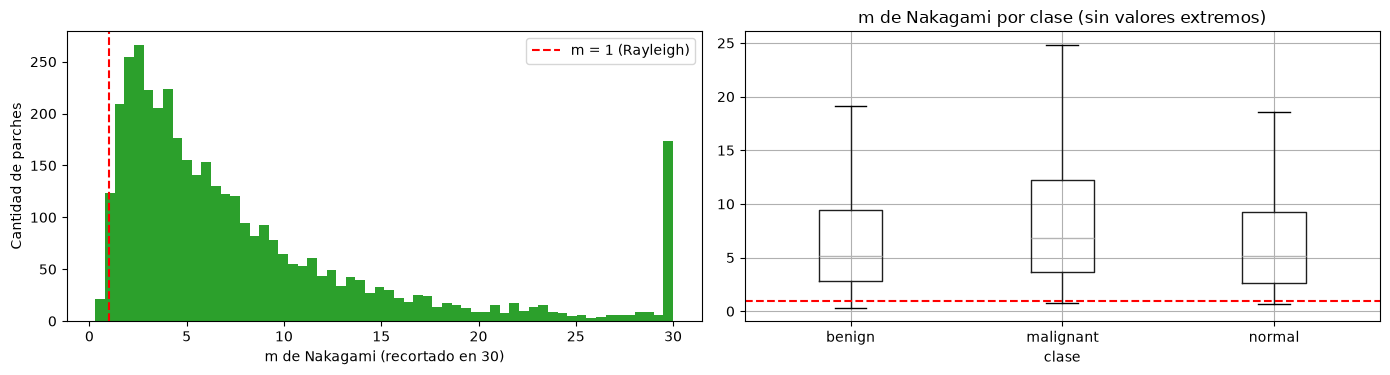

m de Nakagami: mediana por clase
clase
benign       5.18
malignant    6.84
normal       5.12
Name: m_nakagami, dtype: float64

Parches con m < 1,5: 5.7 %


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(parches_df["m_nakagami"].clip(upper=30), bins=60, color="tab:green")
axes[0].axvline(1, color="red", linestyle="--", label="m = 1 (Rayleigh)")
axes[0].set_xlabel("m de Nakagami (recortado en 30)")
axes[0].set_ylabel("Cantidad de parches")
axes[0].legend()

parches_df.boxplot(column="m_nakagami", by="clase", ax=axes[1], showfliers=False)
axes[1].axhline(1, color="red", linestyle="--")
axes[1].set_title("m de Nakagami por clase (sin valores extremos)")
plt.suptitle("")
plt.tight_layout()
plt.show()

print("m de Nakagami: mediana por clase")
print(parches_df.groupby("clase")["m_nakagami"].median().round(2))
print(f"\nParches con m < 1,5: {100 * (parches_df['m_nakagami'] < 1.5).mean():.1f} %")

**Qué vemos:** solo el 5,7 % de los parches tiene $m < 1{,}5$; la mediana de $m$ es ~5 (benignas y normales) y ~7 (malignas). La barra en 30 junta los parches con $m$ todavía más alto (muy regulares). Los parches son **mucho más regulares** (menos dispersos respecto de su media) que lo que predice Rayleigh. Esto no quiere decir que el tejido tenga "más dispersores": como vemos en la sección 7, es el efecto del procesamiento que hace el ecógrafo antes de guardar la imagen.

## 5. Relación media/desvío (μ/σ)

Si el speckle fuera Rayleigh puro, **todos** los parches deberían tener μ/σ ≈ 1,91, sin importar su brillo. Es la predicción más simple y más fácil de verificar.

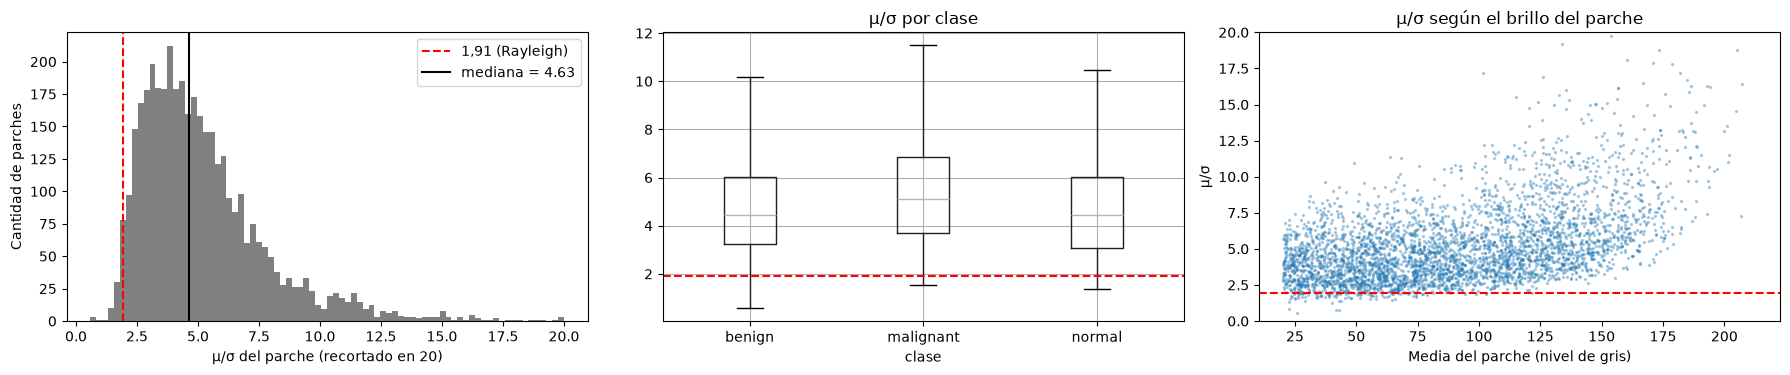

count    3900.00
mean        5.19
std         2.65
min         0.59
5%          2.23
25%         3.35
50%         4.63
75%         6.28
95%        10.55
max        31.61
Name: mu_sigma, dtype: float64

Parches con μ/σ entre 1,7 y 2,1: 2.9 %


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(parches_df["mu_sigma"].clip(upper=20), bins=80, color="gray")
axes[0].axvline(1.91, color="red", linestyle="--", label="1,91 (Rayleigh)")
axes[0].axvline(parches_df["mu_sigma"].median(), color="black", label=f"mediana = {parches_df['mu_sigma'].median():.2f}")
axes[0].set_xlabel("μ/σ del parche (recortado en 20)")
axes[0].set_ylabel("Cantidad de parches")
axes[0].legend()

parches_df.boxplot(column="mu_sigma", by="clase", ax=axes[1], showfliers=False)
axes[1].axhline(1.91, color="red", linestyle="--")
axes[1].set_title("μ/σ por clase")

axes[2].scatter(parches_df["media"], parches_df["mu_sigma"], s=2, alpha=0.3)
axes[2].axhline(1.91, color="red", linestyle="--")
axes[2].set_ylim(0, 20)
axes[2].set_xlabel("Media del parche (nivel de gris)")
axes[2].set_ylabel("μ/σ")
axes[2].set_title("μ/σ según el brillo del parche")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(parches_df["mu_sigma"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2))
print(f"\nParches con μ/σ entre 1,7 y 2,1: {100 * parches_df['mu_sigma'].between(1.7, 2.1).mean():.1f} %")

**Qué vemos:**
- La mediana de μ/σ es **~4,6**, más del doble del 1,91 teórico, y solo ~3 % de los parches cae cerca de 1,91. Las imágenes **no cumplen** la predicción de Rayleigh.
- μ/σ **no es constante**: **crece con el brillo** del parche (gráfico de la derecha). En Rayleigh, σ es proporcional a μ y el cociente no depende del brillo. Acá, en los parches claros σ crece menos que μ.

### 5.1 ¿Difiere entre clases?

En el boxplot las malignas parecen tener μ/σ un poco más alto. Para testearlo **no** podemos usar los ~3900 parches como si fueran independientes, porque 5 parches de la misma imagen se parecen entre sí. Resumimos cada imagen con la **mediana** de sus parches y comparamos imágenes con la U de Mann-Whitney (como en la Parte 0).

Como μ/σ depende del brillo, comparamos también la media de los parches: si una clase tiene tejido más claro, el μ/σ más alto podría deberse solo a eso.

In [11]:
por_imagen = parches_df.groupby(["id", "clase"])[["mu_sigma", "media"]].median().reset_index()
print(por_imagen.groupby("clase")[["mu_sigma", "media"]].median().round(2), "\n")

for columna in ["mu_sigma", "media"]:
    print(f"--- {columna} (mediana por imagen) ---")
    for a, b in [("benign", "malignant"), ("benign", "normal"), ("malignant", "normal")]:
        p = mannwhitneyu(por_imagen[por_imagen["clase"] == a][columna],
                         por_imagen[por_imagen["clase"] == b][columna]).pvalue
        print(f"{a:9s} vs {b:9s}: p = {p:.4f}  ->  {'diferencia significativa' if p < 0.05 else 'sin diferencia significativa'}")

           mu_sigma  media
clase                     
benign         4.46  87.32
malignant      5.05  83.99
normal         4.46  86.77 

--- mu_sigma (mediana por imagen) ---
benign    vs malignant: p = 0.0000  ->  diferencia significativa
benign    vs normal   : p = 0.7839  ->  sin diferencia significativa
malignant vs normal   : p = 0.0043  ->  diferencia significativa
--- media (mediana por imagen) ---
benign    vs malignant: p = 0.2717  ->  sin diferencia significativa
benign    vs normal   : p = 0.9640  ->  sin diferencia significativa
malignant vs normal   : p = 0.3689  ->  sin diferencia significativa


**Qué vemos:**
- Benignas y normales tienen el **mismo** μ/σ (mediana 4,46; p = 0,78).
- Las **malignas tienen μ/σ más alto** (5,05) y la diferencia es **significativa** contra las otras dos (p < 0,001 y p = 0,004).
- El brillo del tejido **no** difiere entre clases (medianas 84–87, p > 0,27), así que la diferencia no se explica porque los parches de las malignas sean más claros.

¿Qué significa? Los parches están **lejos de la lesión**, así que no estamos midiendo el tumor. Hay dos explicaciones posibles, que con estos datos no podemos separar:
1. **Configuración del ecógrafo distinta:** si las malignas se adquirieron con otro rango dinámico, otro nivel de suavizado o más zoom (en la Parte 0 vimos que las malignas tienen anchos de imagen más extremos), el speckle se ve más "liso" sin que el tejido cambie.
2. **Tejido distinto alrededor del tumor maligno** (por ejemplo, reacción del tejido vecino o pacientes de otra edad, con mama más grasa).

**Implicancia para la Parte 6:** un descriptor de textura de la lesión podría estar midiendo en parte *cómo se adquirió la imagen* y no *qué es la lesión*. Por eso conviene usar descriptores **relativos al tejido de la misma imagen** (lesión respecto del anillo que la rodea), como la ecogenicidad relativa de la Parte 0.

## 6. ¿Es multiplicativo? Varianza local vs. media

Ahora miramos **cada píxel** con su vecindad, no parches sueltos. `ruido.varianza_vs_media()` calcula en una ventana de 7 × 7 alrededor de cada píxel:

$$\mu_{local} = \overline{g}, \qquad \text{var}_{local} = \overline{g^2} - \overline{g}^{\,2}$$

usando `scipy.ndimage.uniform_filter` (el filtro promediador de la clase de Mejoramiento) sobre $g$ y sobre $g^2$.

**Qué esperamos:**
- ruido **aditivo**: la varianza **no depende** del brillo;
- ruido **multiplicativo** ($g = f \cdot n$): $\sigma \propto \mu$, o sea $\text{var} \propto \mu^2$;
- **después del log**: la varianza debería quedar constante.

Primero lo vemos como imagen, en un caso:

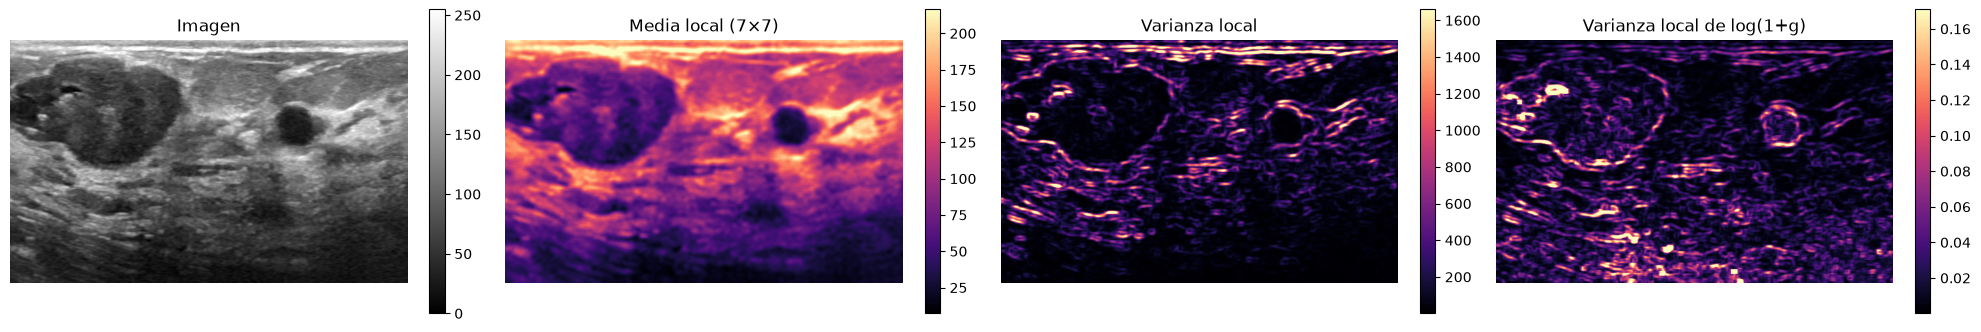

In [12]:
caso = ejemplos[0]
img, mascara = cargar_caso(caso)
media, varianza = ruido.varianza_vs_media(img, ventana=7)
media_log, varianza_log = ruido.varianza_vs_media(np.log1p(img.astype(float)), ventana=7)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (titulo, im) in zip(axes, [("Imagen", img), ("Media local (7×7)", media),
                                   ("Varianza local", varianza), ("Varianza local de log(1+g)", varianza_log)]):
    h = ax.imshow(im, cmap="gray" if titulo == "Imagen" else "magma",
                  vmax=None if titulo == "Imagen" else np.percentile(im, 99))
    ax.set_title(titulo)
    ax.axis("off")
    plt.colorbar(h, ax=ax, fraction=0.035)
plt.tight_layout()
plt.show()

**Qué vemos:**
- La varianza local más alta **no está en el speckle sino en los bordes**: el contorno de las lesiones y las fibras brillantes. En una ventana de 7 × 7 que cae sobre un borde se mezclan dos niveles de gris distintos. Por eso, para estudiar el ruido, vamos a resumir con la **mediana** (que no se deja arrastrar por esos valores extremos) y no con el promedio.
- Dentro del tejido, la varianza de la imagen original es mayor en las zonas claras de arriba que en la zona oscura del fondo.
- Después del log pasa lo contrario: la **zona oscura de abajo** queda con más varianza. El log amplifica las diferencias entre valores chicos (pasar de 10 a 20 es lo mismo que pasar de 100 a 200).

Para cuantificarlo juntamos píxeles de todo el dataset.

Usamos el `log(1 + g)` para que el 0 no dé $-\infty$.

### 6.1 Varianza vs. media en todo el dataset

Para cada imagen tomamos 5000 píxeles al azar de **tejido**: fuera de la lesión dilatada, lejos del fondo negro y de las marcas saturadas (erosionamos la zona válida 7 × 7 para que la ventana entera caiga adentro) y con media local ≥ 20. Agrupamos los píxeles por su **brillo local** (de a 10 niveles de gris) y graficamos la **mediana de la varianza** de cada grupo. En el eje x usamos el brillo original en los dos casos, para poder comparar el antes y el después del log.

En escala **log-log**, una ley $\text{var} \propto \mu^\beta$ es una recta de pendiente $\beta$: multiplicativo ⇒ $\beta = 2$; aditivo ⇒ $\beta = 0$.

3,900,000 píxeles de 780 imágenes
Pendiente β (brillo 20–130):  original = 1.17   después del log = -0.82


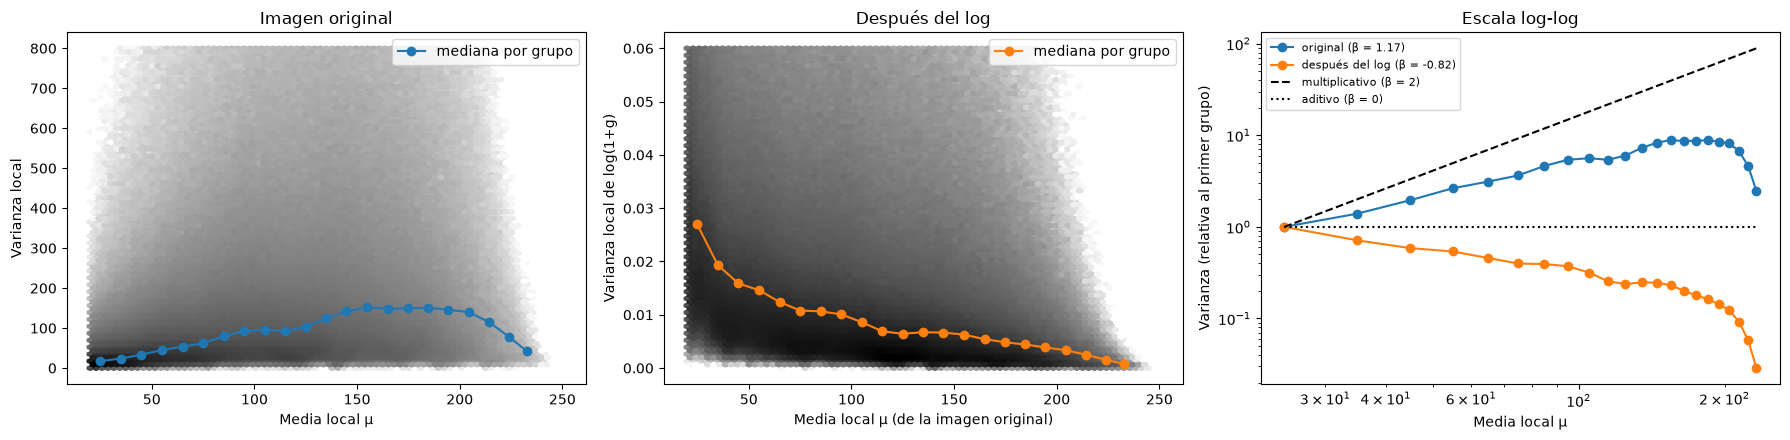

In [13]:
rng = np.random.default_rng(SEED)
disco = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41))
nucleo = np.ones((7, 7), np.uint8)
mu_px, var_px, var_log_px = [], [], []

for _, caso in casos.iterrows():
    img, mascara = cargar_caso(caso)
    lejos_lesion = ~cv2.dilate(mascara.astype(np.uint8), disco).astype(bool)
    sin_fondo_ni_marcas = cv2.erode(((img > 0) & (img < 250)).astype(np.uint8), nucleo).astype(bool)

    media, varianza = ruido.varianza_vs_media(img, ventana=7)
    _, varianza_log = ruido.varianza_vs_media(np.log1p(img.astype(float)), ventana=7)

    validos = np.flatnonzero(lejos_lesion & sin_fondo_ni_marcas & (media >= 20))
    elegidos = rng.choice(validos, size=min(5000, validos.size), replace=False)
    mu_px.append(media.flat[elegidos])
    var_px.append(varianza.flat[elegidos])
    var_log_px.append(varianza_log.flat[elegidos])

mu_px, var_px, var_log_px = map(np.concatenate, (mu_px, var_px, var_log_px))

bordes = np.arange(20, 250, 10)
grupo = np.digitize(mu_px, bordes)
curva = pd.DataFrame({
    "brillo": [np.median(mu_px[grupo == i]) for i in range(1, len(bordes))],
    "var": [np.median(var_px[grupo == i]) for i in range(1, len(bordes))],
    "var_log": [np.median(var_log_px[grupo == i]) for i in range(1, len(bordes))],
    "n": [(grupo == i).sum() for i in range(1, len(bordes))],
})
curva = curva[curva["n"] >= 1000]          # grupos con suficientes píxeles
print(f"{len(mu_px):,} píxeles de {len(casos)} imágenes")

# pendiente beta en log-log, en el rango donde no hay saturación (brillo 20 a 130)
rango = curva["brillo"] <= 130
beta = np.polyfit(np.log(curva.loc[rango, "brillo"]), np.log(curva.loc[rango, "var"]), 1)[0]
beta_log = np.polyfit(np.log(curva.loc[rango, "brillo"]), np.log(curva.loc[rango, "var_log"]), 1)[0]
print(f"Pendiente β (brillo 20–130):  original = {beta:.2f}   después del log = {beta_log:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hexbin(mu_px, var_px, gridsize=80, bins="log", cmap="Greys", extent=(20, 250, 0, 800))
axes[0].plot(curva["brillo"], curva["var"], "o-", color="tab:blue", label="mediana por grupo")
axes[0].set_xlabel("Media local μ")
axes[0].set_ylabel("Varianza local")
axes[0].set_title("Imagen original")
axes[0].legend()

axes[1].hexbin(mu_px, var_log_px, gridsize=80, bins="log", cmap="Greys", extent=(20, 250, 0, 0.06))
axes[1].plot(curva["brillo"], curva["var_log"], "o-", color="tab:orange", label="mediana por grupo")
axes[1].set_xlabel("Media local μ (de la imagen original)")
axes[1].set_ylabel("Varianza local de log(1+g)")
axes[1].set_title("Después del log")
axes[1].legend()

ref = curva["brillo"]
axes[2].loglog(ref, curva["var"] / curva["var"].iloc[0], "o-", label=f"original (β = {beta:.2f})")
axes[2].loglog(ref, curva["var_log"] / curva["var_log"].iloc[0], "o-", label=f"después del log (β = {beta_log:.2f})")
axes[2].loglog(ref, (ref / ref.iloc[0]) ** 2, "k--", label="multiplicativo (β = 2)")
axes[2].loglog(ref, np.ones(len(ref)), "k:", label="aditivo (β = 0)")
axes[2].set_xlabel("Media local μ")
axes[2].set_ylabel("Varianza (relativa al primer grupo)")
axes[2].set_title("Escala log-log")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Qué vemos:**
- **Imagen original (azul):** la varianza **crece con el brillo** entre 20 y ~150 niveles de gris, con pendiente **β ≈ 1,17** en log-log. Es una dependencia real con el brillo (no es ruido aditivo, β = 0), pero **bastante más débil que la de un ruido multiplicativo puro** (β = 2). Por encima de ~150 la varianza se **aplana** y desde ~200 **cae**: los píxeles se acercan a 255 y se saturan, y un valor recortado no puede variar.
- **Después del log (naranja):** la varianza no queda constante sino que **disminuye** con el brillo (β ≈ −0,82). El log no "aditivizó" el ruido: lo **sobrecorrigió**.

¿Por qué? Si el ruido fuera multiplicativo puro (β = 2), el log lo dejaría plano (β = 0): el log resta 2 a la pendiente. Partimos de β ≈ 1,2 y llegamos a β ≈ −0,8, es decir, le restó ~2, como predice la teoría. El problema es que **la imagen ya venía parcialmente comprimida**: el ecógrafo ya había aplicado una compresión logarítmica, y nuestro log es un segundo log encima. Lo vemos en detalle en la sección 7.

## 7. Por qué las imágenes no cumplen la teoría

La teoría de Rayleigh describe la **amplitud del eco (la envolvente)**, pero lo que guarda el ecógrafo, y lo que tenemos en BUSI, es una imagen **procesada para que la vea un médico**. Entre una cosa y la otra pasan, por lo menos, tres cosas:

1. **Compresión logarítmica.** La amplitud del eco tiene un rango dinámico enorme (de 60 a 100 dB): un reflector fuerte puede ser 100 000 veces más intenso que el tejido graso. Para que entre en 256 niveles de gris, el ecógrafo aplica algo como $g = D \cdot \ln(A) + G$, donde $D$ depende del rango dinámico elegido y $G$ es la ganancia.
2. **Post-procesamiento.** Filtros de suavizado y "reducción de speckle" propios del equipo, realce de bordes, interpolación al convertir las líneas del barrido a la grilla de píxeles, y un mapa de grises (curva de contraste) que no es exactamente logarítmico.
3. **Recorte (clipping).** Lo que pasa de 255 se satura y lo que baja del umbral de rechazo se pone en negro.

Cada uno deja una huella que podemos buscar en los datos.

### 7.1 La huella de la compresión logarítmica

Si $A$ es Rayleigh y $g = D \ln A + G$, entonces el desvío de $g$ es $D \cdot \sigma_{\ln A}$, y para Rayleigh $\sigma_{\ln A} = \pi / \sqrt{24} \approx 0{,}64$ **siempre**, sin importar la escala. Entonces:

- **el desvío σ de un parche debería ser constante** (no depender del brillo): el ruido pasa a ser **aditivo**;
- por eso **μ/σ crece con el brillo**, que es justamente lo que vimos en la sección 5;
- y despejando, $D \approx \sigma / 0{,}64$: podemos **estimar** el factor de compresión con cada parche.

Graficamos el desvío de cada parche contra su media:

              parches  sigma  mu_sigma  D estimado
grupo_brillo                                      
(20, 40]          563   7.45      3.86       11.61
(40, 60]          614  13.28      3.77       20.71
(60, 80]          580  17.66      3.96       27.55
(80, 100]         511  21.15      4.23       32.97
(100, 130]        812  23.11      5.00       36.03
(130, 160]        604  23.75      6.06       37.03
(160, 250]        216  21.01      8.27       32.76


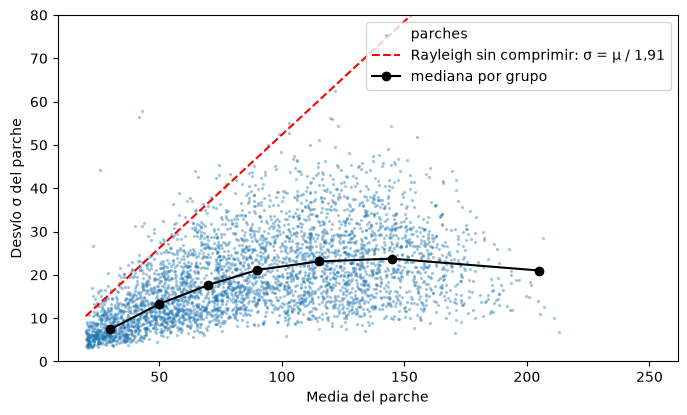

In [14]:
SIGMA_LN_RAYLEIGH = np.pi / np.sqrt(24)          # desvío de ln(A) si A es Rayleigh ≈ 0,641

parches_df["grupo_brillo"] = pd.cut(parches_df["media"], [20, 40, 60, 80, 100, 130, 160, 250])
resumen = parches_df.groupby("grupo_brillo", observed=True).agg(
    parches=("desvio", "size"), sigma=("desvio", "median"), mu_sigma=("mu_sigma", "median"))
resumen["D estimado"] = resumen["sigma"] / SIGMA_LN_RAYLEIGH
print(resumen.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(parches_df["media"], parches_df["desvio"], s=2, alpha=0.3, label="parches")
x = np.linspace(20, 250, 100)
ax.plot(x, x / 1.91, "r--", label="Rayleigh sin comprimir: σ = μ / 1,91")
ax.plot([iv.mid for iv in resumen.index], resumen["sigma"], "ko-", label="mediana por grupo")
ax.set_xlabel("Media del parche")
ax.set_ylabel("Desvío σ del parche")
ax.set_ylim(0, 80)
ax.legend()
plt.show()

**Qué vemos:**
- Los parches quedan **muy por debajo** de la recta σ = μ/1,91 que tendría Rayleigh sin comprimir: para el mismo brillo, tienen mucho menos desvío.
- El desvío **crece** con el brillo hasta μ ≈ 100 y después **se estabiliza en σ ≈ 21–24** niveles de gris. Ese **plateau** es exactamente la huella de la compresión logarítmica: en el tejido claro el ruido es aproximadamente aditivo, con σ constante, y por eso μ/σ crece con el brillo (de 4,2 a 8,3 en la tabla).
- En ese rango el factor de compresión estimado es **D ≈ 33–37** (σ ≈ 23 / 0,64), bastante estable. En cambio, en el tejido **oscuro** (μ < 80) σ es menor y el D "estimado" baja hasta ~12: ahí el modelo $D \ln A + G$ con un D único **no** describe la imagen. Probablemente el mapa de grises del equipo no es un log puro en los niveles bajos (curva de contraste, umbral de rechazo de ecos débiles) y hay menos señal.

### 7.2 ¿Y si deshacemos la compresión?

Si la imagen es $g = D \ln A + G$, podemos intentar **volver a la amplitud** con $A \propto e^{g/D}$ (la ganancia $G$ solo cambia la escala de $A$, que no afecta μ/σ ni la forma). No conocemos $D$, así que probamos con varios valores alrededor del estimado en 7.1 y vemos si los parches "descomprimidos" se acercan a Rayleigh.

Usamos solo los parches con media ≥ 80, donde σ es aproximadamente constante y el modelo logarítmico es más creíble. Para no tardar demasiado tomamos uno de cada 3.

In [15]:
claros = parches_df.index[parches_df["media"] >= 80]
parches_claros = [todos_los_parches[i] for i in claros[::3]]     # uno de cada 3

filas = []
for D in [20, 30, 40, 50, 60]:
    for p in parches_claros:
        amplitud = np.exp(p.astype(float) / D)
        res = ruido.ajustar_distribuciones(amplitud)
        filas.append({"D": D, "μ/σ": ruido.razon_media_desvio(amplitud),
                      "m Nakagami": res["nakagami"]["params"][0],
                      "KS D Rayleigh": res["rayleigh"]["ks"],
                      "Rayleigh mejor (AIC)": min(res, key=lambda n: res[n]["aic"]) == "rayleigh"})
descomprimido = pd.DataFrame(filas)
print(f"{len(parches_claros)} parches con media ≥ 80\n")
print("Original (sin descomprimir): KS D Rayleigh mediano =",
      parches_df.loc[claros, "ks_rayleigh"].median().round(3))
resumen_d = descomprimido.groupby("D")[["μ/σ", "m Nakagami", "KS D Rayleigh"]].median()
resumen_d["% Rayleigh mejor (AIC)"] = 100 * descomprimido.groupby("D")["Rayleigh mejor (AIC)"].mean()
resumen_d.round(3)

715 parches con media ≥ 80

Original (sin descomprimir): KS D Rayleigh mediano = 0.366


,μ/σ,m Nakagami,KS D Rayleigh,% Rayleigh mejor (AIC)
D,,,,
20,0.707,0.281,0.483,0.14
30,1.149,0.546,0.292,0.14
40,1.605,0.898,0.217,0.42
50,2.078,1.353,0.211,0.28
60,2.524,1.915,0.230,0.00


**Qué vemos:**
- Al "descomprimir", μ/σ y el $m$ de Nakagami **bajan** a medida que D crece, y para **D entre 40 y 50** quedan en los valores de Rayleigh (μ/σ ≈ 1,91, $m \approx 1$). O sea, **un solo factor de compresión razonable alcanza para llevar las estadísticas de primer orden a las de Rayleigh**. Ese D (~45) es algo mayor que el estimado con σ en 7.1 (~35), lo que es coherente con que el equipo además **suavice** la imagen: el suavizado achica σ y hace que la estimación de 7.1 quede baja.
- El ajuste de Rayleigh **mejora** (KS D baja de 0,37 a ~0,21) pero **no alcanza**: sigue muy lejos del de Gamma (~0,08) y Rayleigh es la mejor por AIC en menos del 0,5 % de los parches. La **forma** del histograma sigue sin ser la de Rayleigh.

Es decir: la compresión logarítmica explica **la mayor parte** del desvío respecto de la teoría (μ/σ alto, $m$ alto, σ constante en el tejido claro), pero no todo. Lo que queda se atribuye al **post-procesamiento** del ecógrafo (suavizado, interpolación, mapa de grises no logarítmico, saturación), a la **cuantización** en 256 niveles y a que muchos parches tienen algo de **estructura** (fibras) y no son speckle puro. Sin acceso a los datos crudos (RF) del equipo no se puede invertir todo ese procesamiento.

### 7.3 Resumen: qué parte de la teoría vale y qué parte no

| Predicción teórica | Qué encontramos en BUSI | Por qué |
|---|---|---|
| Histograma de Rayleigh | Rayleigh casi nunca gana; Gamma (~64 %) y Nakagami (~35 %) ajustan mucho mejor | La imagen no es la amplitud del eco sino su versión comprimida y procesada |
| μ/σ ≈ 1,91 constante | Mediana ~4,6, y crece con el brillo | La compresión log vuelve el desvío casi constante ⇒ μ/σ ∝ μ |
| var ∝ μ² (multiplicativo) | var crece con μ pero más lento (β ≈ 1,2) y se aplana en el tejido claro | Régimen intermedio: compresión log + mapa de grises no lineal + saturación |
| Después del log, var constante | La varianza **disminuye** con el brillo (β ≈ −0,8) | Aplicamos un segundo log sobre una imagen que ya estaba comprimida |
| Píxeles independientes | El speckle forma granos de varios píxeles | Celda de resolución finita + interpolación y suavizado del equipo |

## 8. Conclusiones

Analizamos 3900 parches de tejido (5 por imagen, de las 780 imágenes) y 3,9 millones de píxeles de tejido de BUSI.

1. **El speckle de BUSI no es Rayleigh.** Rayleigh es la mejor distribución en solo el 0,3 % de los parches y su KS D mediano (0,33) es cuatro veces el de las otras. **Gamma** es la que mejor describe el ruido (mejor AIC en el 64 % de los parches), seguida muy de cerca por **Nakagami** (35 %), con $m$ mediano ≈ 5, muy lejos de $m = 1$.
2. **La relación μ/σ no es 1,91 ni es constante:** su mediana es 4,6, solo el 3 % de los parches está cerca de 1,91, y crece con el brillo del parche.
3. **El ruido depende del brillo, pero no es multiplicativo puro:** la varianza local crece con la media con β ≈ 1,2 (no 2) entre 20 y 150 niveles de gris, se aplana en el tejido claro y cae cerca de la saturación. Aplicar log no la vuelve constante sino que la invierte (β ≈ −0,8).
4. **La causa principal es la compresión logarítmica del ecógrafo.** En el tejido claro el desvío es casi constante (σ ≈ 23), que es lo que predice la compresión logarítmica de una amplitud Rayleigh, con un factor D ≈ 35–45. "Descomprimiendo" con un D en ese rango, μ/σ y $m$ vuelven a valores de Rayleigh, aunque la forma del histograma sigue sin coincidir por el post-procesamiento del equipo (suavizado, interpolación, mapa de grises) y la cuantización.
5. **El comportamiento es el mismo en las tres clases** (Gamma > Nakagami >> Rayleigh), pero el tejido de las imágenes **malignas** tiene un μ/σ significativamente más alto (5,05 vs. 4,46) con el mismo brillo. Puede ser un efecto de adquisición, y hay que tenerlo en cuenta en la Parte 6.
6. **Los píxeles no son independientes:** el speckle forma granos de varios píxeles. Por eso el test KS rechaza casi todo (p-valores demasiado chicos) y usamos D y AIC para comparar modelos.

**Qué implica para las partes siguientes:**
- **Parte 3 (filtrado):** como en BUSI el ruido es aproximadamente **aditivo en el tejido claro** y solo débilmente dependiente del brillo en el oscuro, aplicar log antes de filtrar **no** es necesario (y de hecho sobrecorrige). Los filtros lineales (promediador, gaussiano, pasabajos) se pueden aplicar directamente sobre la imagen.
- **Parte 4 (mapas):** el desvío local depende del brillo en el tejido oscuro, así que la **varianza local** y el **coeficiente de variación** (σ/μ) van a separar lesión (oscura) de tejido en parte solo por brillo. Además, como el speckle tiene granos de varios píxeles, las ventanas de los mapas tienen que ser varias veces más grandes que un grano.
- **Parte 6 (descriptores):** usar descriptores de textura **relativos al tejido de la misma imagen**, por la diferencia de μ/σ entre clases que aparece incluso lejos de la lesión.

**Limitaciones:** el filtro de marcas por saturación (≥ 250) no detecta marcas grises (líneas punteadas); cuando esté la Parte 1 conviene repetir el análisis sobre las imágenes con inpainting. Y "lejos de la lesión" no garantiza "homogéneo": algunos parches incluyen fibras.